In [1]:

import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Chercher la base selon l'emplacement du notebook
candidats = [Path("../analysis.db"), Path("analysis.db")]
db_path = next((p.resolve() for p in candidats if p.exists()), None)

if db_path is None:
    raise FileNotFoundError(
        "Base analysis.db introuvable. Vérifie son emplacement."
    )

conn = sqlite3.connect(str(db_path))

df = pd.read_sql_query("SELECT * FROM sales", conn)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

print("Dimensions :", df.shape)
print("Période :", df["InvoiceDate"].min(), "à", df["InvoiceDate"].max())

df.head()


Dimensions : (536641, 8)
Période : 2010-12-01 08:26:00 à 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

# Conserver les ventes positives avec un client identifiable
ventes = df[
    df["CustomerID"].notna()
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

# Calculer le montant de chaque ligne
ventes["Montant"] = ventes["Quantity"] * ventes["UnitPrice"]

print("Lignes de vente retenues :", len(ventes))
print("Clients identifiables :", ventes["CustomerID"].nunique())
print("Commandes retenues :", ventes["InvoiceNo"].nunique())


Lignes de vente retenues : 392692
Clients identifiables : 4338
Commandes retenues : 18532


In [3]:

# Date de référence : lendemain du dernier achat observé
date_reference = ventes["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = ventes.groupby("CustomerID").agg(
    Recence=("InvoiceDate", lambda dates:
             (date_reference - dates.max().normalize()).days),
    Frequence=("InvoiceNo", "nunique"),
    Valeur_monetaire=("Montant", "sum")
).reset_index()

rfm["CustomerID"] = rfm["CustomerID"].astype("Int64")

print("Date de référence :", date_reference.date())
print("Nombre de clients analysés :", len(rfm))

rfm.head()


Date de référence : 2011-12-10
Nombre de clients analysés : 4338


,CustomerID,Recence,Frequence,Valeur_monetaire
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40


In [4]:

# Utiliser les rangs pour gérer les valeurs identiques
rfm["R_score"] = pd.qcut(
    rfm["Recence"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["Frequence"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["Valeur_monetaire"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"] + rfm["F_score"] + rfm["M_score"]
)

rfm.head()


,CustomerID,Recence,Frequence,Valeur_monetaire,R_score,F_score,M_score,RFM_score
0,12346,326,1,77183.60,1,1,4,6
1,12347,3,7,4310.00,4,4,4,12
2,12348,76,4,1797.24,2,3,4,9
3,12349,19,1,1757.55,3,1,4,8
4,12350,311,1,334.40,1,1,2,4


In [5]:

def segmenter_client(row):
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "Meilleurs clients"
    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Clients fidèles récents"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "Clients à réactiver"
    elif row["F_score"] <= 2 and row["R_score"] >= 3:
        return "Nouveaux ou occasionnels"
    else:
        return "Autres clients"

rfm["Segment"] = rfm.apply(segmenter_client, axis=1)

resume_segments = (
    rfm.groupby("Segment", observed=True)
    .agg(
        Nombre_clients=("CustomerID", "count"),
        Depense_totale=("Valeur_monetaire", "sum"),
        Depense_moyenne=("Valeur_monetaire", "mean")
    )
    .sort_values("Nombre_clients", ascending=False)
    .round(2)
)

resume_segments


,Nombre_clients,Depense_totale,Depense_moyenne
Segment,,,
Autres clients,1513,771526.22,509.93
Meilleurs clients,1312,6477238.54,4936.92
Clients à réactiver,656,1052418.71,1604.30
Nouveaux ou occasionnels,656,493338.21,752.04
Clients fidèles récents,201,92687.21,461.13


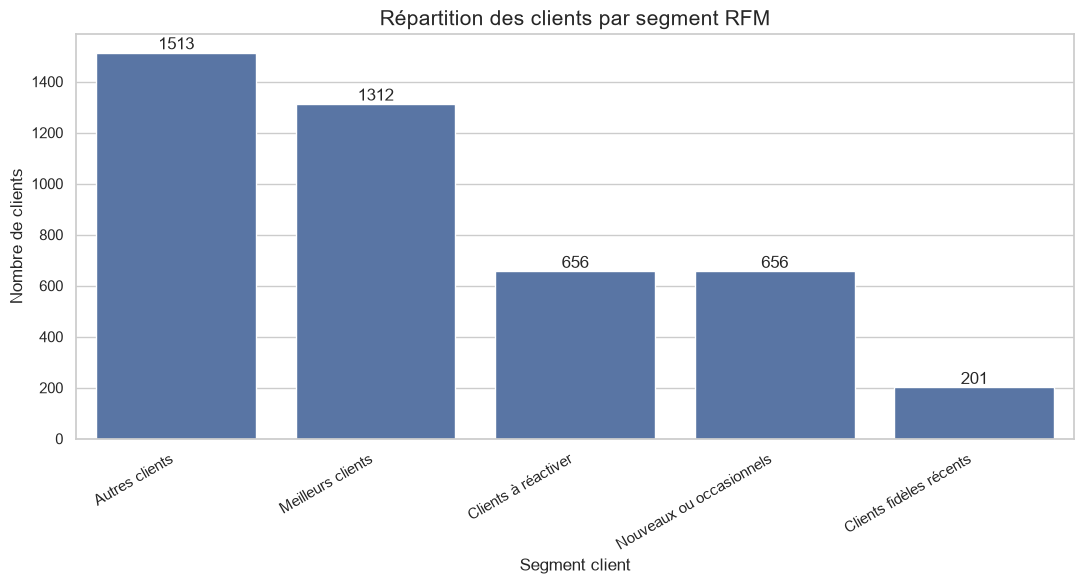

In [6]:

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=rfm,
    x="Segment",
    y="CustomerID",
    estimator="count",
    errorbar=None,
    order=rfm["Segment"].value_counts().index
)

plt.title("Répartition des clients par segment RFM", fontsize=15)
plt.xlabel("Segment client")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=30, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()


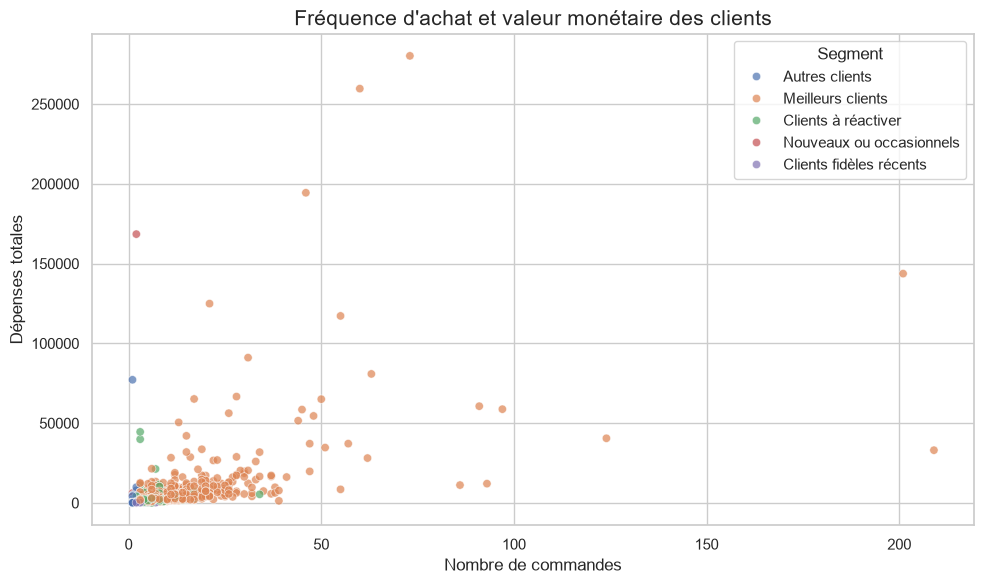

In [7]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequence",
    y="Valeur_monetaire",
    hue="Segment",
    alpha=0.7
)

plt.title("Fréquence d'achat et valeur monétaire des clients", fontsize=15)
plt.xlabel("Nombre de commandes")
plt.ylabel("Dépenses totales")
plt.tight_layout()
plt.show()


L'analyse RFM a permis de segmenter les clients selon la récence de leurs achats, la fréquence de leurs commandes et le montant total dépensé. Cette segmentation permet de distinguer les meilleurs clients, les clients fidèles récents, les clients à réactiver et les clients occasionnels.

Sur le plan commercial, l'entreprise peut chercher à fidéliser ses meilleurs clients, encourager les achats répétés des clients occasionnels et lancer des campagnes ciblées pour reconquérir les clients qui n'ont pas acheté récemment.

Les décisions doivent être adaptées aux effectifs et aux montants observés dans chaque segment. La récence est calculée par rapport à la dernière date présente dans le jeu de données : elle ne représente donc pas nécessairement la situation actuelle des clients.